# 01 — Exploring Galaxy10 DECaLS

Goal: understand what is inside the dataset before training anything.

- What arrays does the file contain, and what are their shapes?
- How many images per class (is the dataset balanced)?
- What do the galaxies of each class look like?

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/Galaxy10_DECals_NoDuplicated.h5"

CLASS_NAMES = [
    "Disturbed",
    "Merging",
    "Round Smooth",
    "In-between Round Smooth",
    "Cigar Shaped Smooth",
    "Barred Spiral",
    "Unbarred Tight Spiral",
    "Unbarred Loose Spiral",
    "Edge-on without Bulge",
    "Edge-on with Bulge",
]

## What is inside the file

An HDF5 file is like a folder of named arrays. We open it *lazily*: nothing is loaded into memory until we ask for it
(all 17,675 images would take ~3.5 GB of RAM).

In [2]:
with h5py.File(DATA_PATH, "r") as f:
    for name, ds in f.items():
        print(f"{name:10s} shape={str(ds.shape):22s} dtype={ds.dtype}")
    labels = f["ans"][:]          # small: one number per image
    redshift = f["redshift"][:]

ans        shape=(17675,)               dtype=uint8
dec        shape=(17675,)               dtype=float64
images     shape=(17675, 256, 256, 3)   dtype=uint8
pxscale    shape=(17675,)               dtype=float64
ra         shape=(17675,)               dtype=float64
redshift   shape=(17675,)               dtype=float64


- `images` — N × 256 × 256 × 3: height, width, and 3 colour channels (g, r, z bands of the telescope, shown as RGB). Values 0–255 (`uint8`).
- `ans` — the label (class number 0–9) of each image. **This is what the model has to predict.**
- `ra`, `dec` — position of the galaxy on the sky; `redshift` — how far away it is; `pxscale` — arcseconds per pixel.

## Class balance

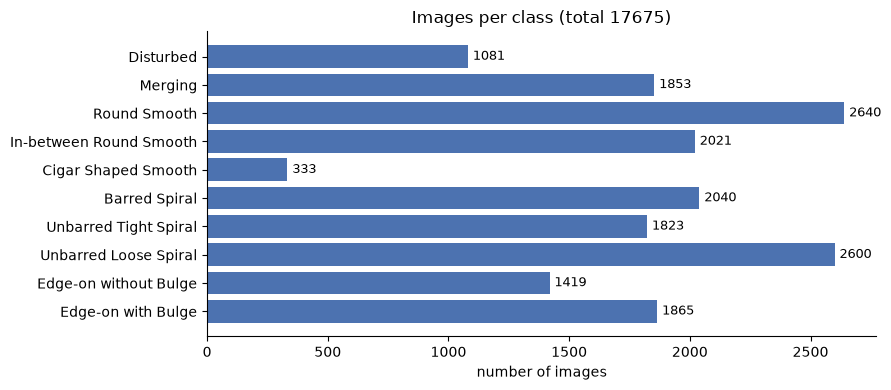

largest / smallest class: 7.9x


In [3]:
counts = np.bincount(labels, minlength=10)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(CLASS_NAMES, counts, color="#4C72B0")
ax.invert_yaxis()
for i, c in enumerate(counts):
    ax.text(c + 20, i, str(c), va="center", fontsize=9)
ax.set_xlabel("number of images")
ax.set_title(f"Images per class (total {counts.sum()})")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../results/class_counts.png", dpi=120)
plt.show()

print(f"largest / smallest class: {counts.max() / counts.min():.1f}x")

The dataset is **imbalanced**: "Cigar Shaped Smooth" has far fewer images than the others.
A model could mostly ignore that class and still get high overall accuracy, so later we should look at
per-class metrics (precision / recall per class, confusion matrix), not only accuracy.

## Example images from each class

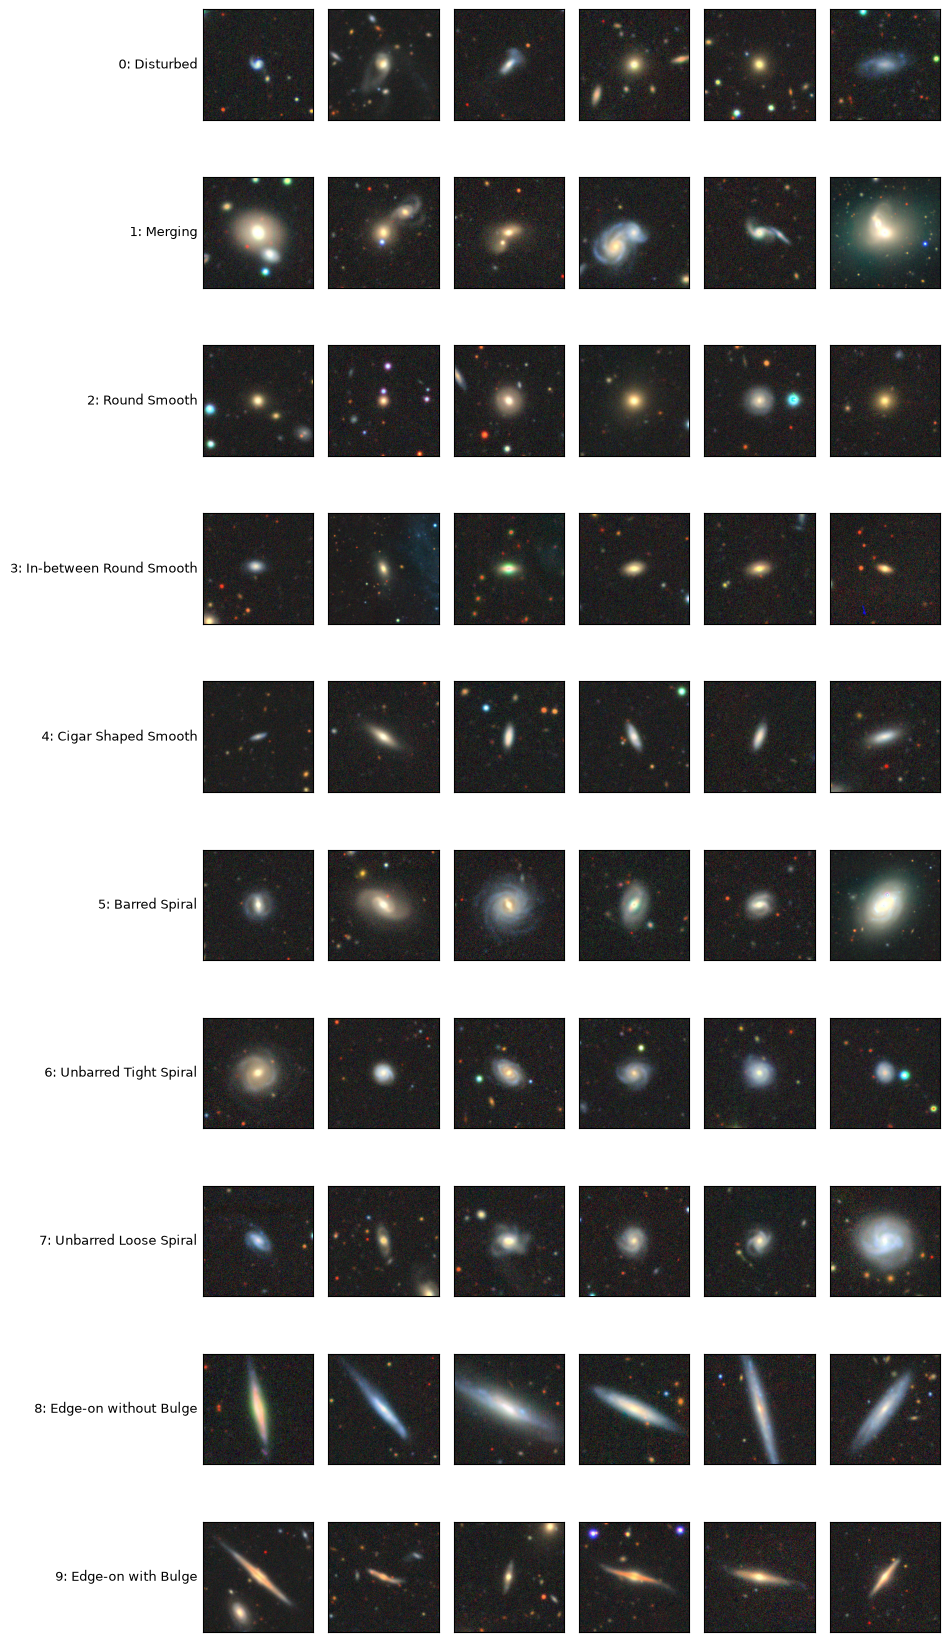

In [4]:
N_PER_CLASS = 6
rng = np.random.default_rng(42)   # fixed seed -> the same examples every run

fig, axes = plt.subplots(10, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, 10 * 1.7))
with h5py.File(DATA_PATH, "r") as f:
    images = f["images"]
    for c in range(10):
        idx = np.sort(rng.choice(np.flatnonzero(labels == c), N_PER_CLASS, replace=False))
        for j, i in enumerate(idx):
            ax = axes[c, j]
            ax.imshow(images[i])
            ax.set_xticks([]); ax.set_yticks([])
        axes[c, 0].set_ylabel(f"{c}: {CLASS_NAMES[c]}", rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../results/examples_per_class.png", dpi=100)
plt.show()

## Redshift (distance) per class

Not needed for training, but a useful sanity check of the metadata.

Some galaxies have no measured redshift (stored as `NaN`). `boxplot` cannot compute a median of a group
that contains `NaN`, so it would draw nothing — we drop them first.

galaxies without redshift: 92 of 17675


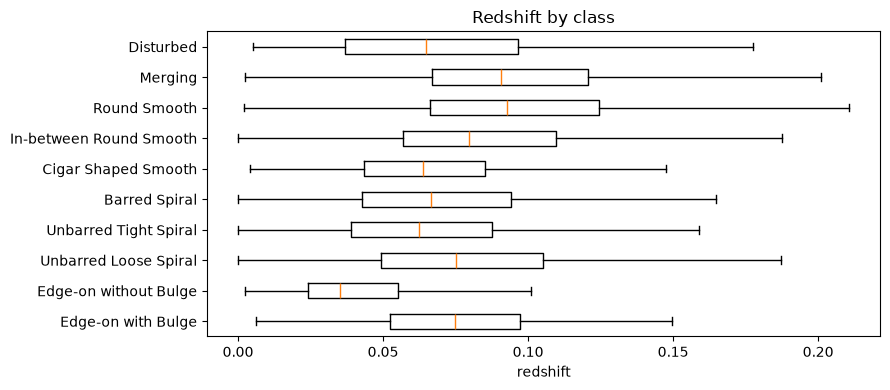

In [5]:
missing = np.isnan(redshift)
print(f"galaxies without redshift: {missing.sum()} of {redshift.size}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([redshift[(labels == c) & ~missing] for c in range(10)], orientation="horizontal",
           tick_labels=CLASS_NAMES, showfliers=False)
ax.invert_yaxis()
ax.set_xlabel("redshift")
ax.set_title("Redshift by class")
plt.tight_layout()
plt.show()